# EduGuard: AI-based Dropout Prediction and Counselling Support
**Data Science Ecosystem (23CS2024) · SIH 2025 problem statement SIH25102**

This notebook contains the complete analysis behind the project report. Run it on **Google Colab**:
1. Open the notebook in Colab.
2. Upload `data.csv` (UCI *Predict Students' Dropout and Academic Success*, separator `;`) using the **Files** panel on the left.
3. Click **Runtime → Run all**.

All random steps use `random_state = 42`, so the results match the report.

## 1. Setup: import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.cluster.hierarchy import dendrogram, linkage

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve,
                             r2_score, mean_squared_error, silhouette_score)
from sklearn.metrics.pairwise import cosine_similarity

RANDOM_STATE = 42
pd.set_option("display.width", 140)

## 2. Load the data (Module 2: import, select, missing values)
The file uses `;` as the separator. We create the binary target **Dropout = 1** if the student dropped out, else 0.

In [2]:
import os
path = next(p for p in ["data.csv", "/content/data.csv", "../data/data.csv"] if os.path.exists(p))
df = pd.read_csv(path, sep=";")
df.columns = [c.strip() for c in df.columns]          # one header contains a stray tab
df["Dropout"] = (df["Target"] == "Dropout").astype(int)
print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
df.head()

Shape: (4424, 38)
Missing values: 0


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target,Dropout
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout,1
1,1,15,1,9254,1,1,160.0,1,1,3,...,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate,0
2,1,1,5,9070,1,1,122.0,1,37,37,...,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout,1
3,1,17,2,9773,1,1,122.0,1,38,37,...,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate,0
4,2,39,1,8014,0,1,100.0,1,37,38,...,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate,0


In [3]:
# Target counts and dropout rate
print(df["Target"].value_counts())
print("Dropout rate:", round(df["Dropout"].mean(), 4))

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64
Dropout rate: 0.3212


In [4]:
# Select, filter, sort and rank examples
S1A, S1G = "Curricular units 1st sem (approved)", "Curricular units 1st sem (grade)"
S2A, S2G = "Curricular units 2nd sem (approved)", "Curricular units 2nd sem (grade)"
unpaid = df[df["Tuition fees up to date"] == 0]                     # filter
print("Students with unpaid fees:", len(unpaid), "| their dropout rate:", round(unpaid["Dropout"].mean(), 3))
top = df.sort_values("Admission grade", ascending=False)[["Admission grade", "Target"]].head()   # sort
top["rank"] = df["Admission grade"].rank(ascending=False)[top.index]                         # rank
top

Students with unpaid fees: 528 | their dropout rate: 0.866


,Admission grade,Target,rank
702,190.0,Dropout,2.0
1673,190.0,Graduate,2.0
2511,190.0,Enrolled,2.0
1888,184.4,Graduate,4.0
1126,184.0,Graduate,5.0


## 3. Exploratory data analysis and visualisation (Modules 2 and 3)

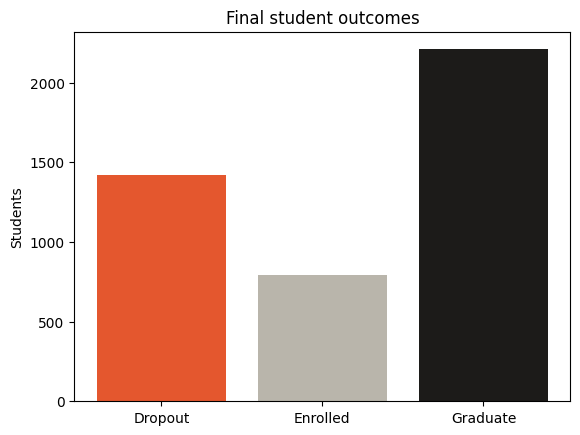

In [5]:
# Count plot of the three original outcomes
counts = df["Target"].value_counts().reindex(["Dropout", "Enrolled", "Graduate"])
plt.bar(counts.index, counts.values, color=["#e4572e", "#b9b5ab", "#1c1b19"])
plt.ylabel("Students"); plt.title("Final student outcomes"); plt.show()

In [6]:
# Descriptive statistics: mean, median, variance, standard deviation
cols = ["Age at enrollment", "Admission grade", S1A, S1G, S2G]
df[cols].agg(["mean", "median", "var", "std"]).T.round(2)

,mean,median,var,std
Age at enrollment,23.27,20.00,57.57,7.59
Admission grade,126.98,126.10,209.73,14.48
Curricular units 1st sem (approved),4.71,5.00,9.57,3.09
Curricular units 1st sem (grade),10.64,12.29,23.46,4.84
Curricular units 2nd sem (grade),10.23,12.20,27.15,5.21


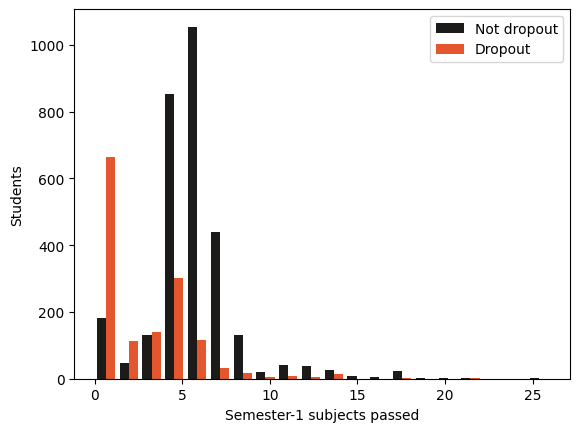

In [7]:
# Histogram: semester-1 subjects passed, dropouts vs others
plt.hist([df.loc[df.Dropout == 0, S1A], df.loc[df.Dropout == 1, S1A]], bins=20,
         color=["#1c1b19", "#e4572e"], label=["Not dropout", "Dropout"])
plt.xlabel("Semester-1 subjects passed"); plt.ylabel("Students"); plt.legend(); plt.show()

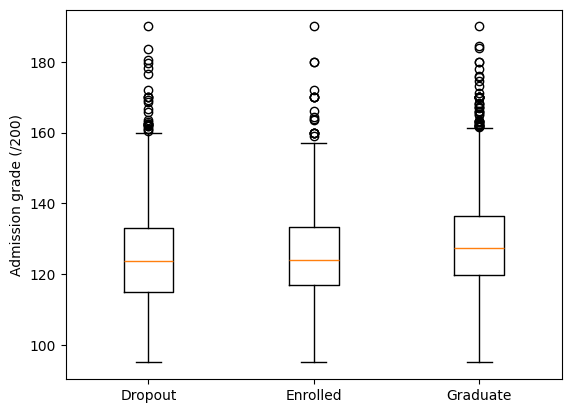

In [8]:
# Box plot: admission grade by outcome
order = ["Dropout", "Enrolled", "Graduate"]
plt.boxplot([df.loc[df.Target == t, "Admission grade"] for t in order], tick_labels=order)
plt.ylabel("Admission grade (/200)"); plt.show()

In [9]:
# Group: dropout rate by fees, debt, scholarship and gender
for col in ["Tuition fees up to date", "Debtor", "Scholarship holder", "Gender"]:
    print(col, df.groupby(col)["Dropout"].mean().round(3).to_dict())

Tuition fees up to date {0: 0.866, 1: 0.247}
Debtor {0: 0.283, 1: 0.62}
Scholarship holder {0: 0.387, 1: 0.122}
Gender {0: 0.251, 1: 0.451}


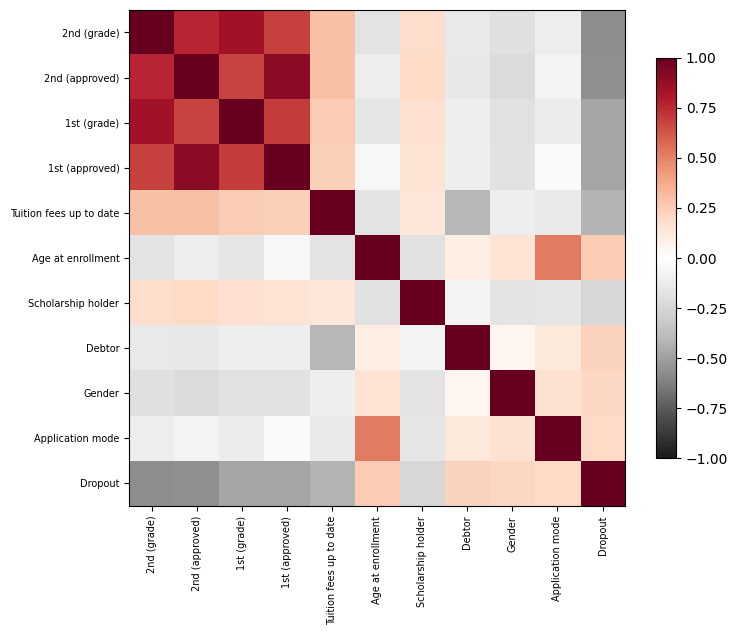

Curricular units 2nd sem (grade)      -0.572
Curricular units 2nd sem (approved)   -0.570
Curricular units 1st sem (grade)      -0.481
Curricular units 1st sem (approved)   -0.479
Tuition fees up to date               -0.429
Age at enrollment                      0.254
Scholarship holder                    -0.245
Debtor                                 0.229
Name: Dropout, dtype: float64

In [10]:
# Correlation heatmap of the 10 features most related to dropout
corr_all = df.select_dtypes("number").corr()["Dropout"].drop("Dropout")
top10 = corr_all.abs().sort_values(ascending=False).index[:10].tolist()
corr = df[top10 + ["Dropout"]].corr()
plt.figure(figsize=(8, 6.5)); plt.imshow(corr, cmap="RdGy_r", vmin=-1, vmax=1); plt.colorbar(shrink=.8)
short = [c.replace("Curricular units ", "").replace(" sem", "") for c in corr]
plt.xticks(range(len(corr)), short, rotation=90, fontsize=7); plt.yticks(range(len(corr)), short, fontsize=7)
plt.show()
corr_all.reindex(corr_all.abs().sort_values(ascending=False).index).head(8).round(3)

## 4. Statistical inference (Module 3: estimation and hypothesis testing)
- **95% confidence interval** for the overall dropout rate.
- **t-test** — H0: dropouts and other students pass the same mean number of semester-1 subjects; H1: the means differ.
- **Chi-square test** — H0: dropout is independent of scholarship status; H1: they are related.

In [11]:
p, n = df["Dropout"].mean(), len(df)
half = 1.96 * np.sqrt(p * (1 - p) / n)
print(f"95% CI for the dropout rate: {p - half:.4f} to {p + half:.4f}")

t, p_t = stats.ttest_ind(df.loc[df.Dropout == 1, S1A], df.loc[df.Dropout == 0, S1A], equal_var=False)
print(f"t-test: t = {t:.2f}, p = {p_t:.2g}  -> reject H0" if p_t < 0.05 else "fail to reject H0")

chi2, p_c, dof, _ = stats.chi2_contingency(pd.crosstab(df["Scholarship holder"], df["Dropout"]))
print(f"Chi-square: chi2 = {chi2:.1f}, dof = {dof}, p = {p_c:.2g}  -> reject H0" if p_c < 0.05 else "fail to reject H0")

95% CI for the dropout rate: 0.3074 to 0.3350
t-test: t = -35.32, p = 1.4e-223  -> reject H0
Chi-square: chi2 = 265.1, dof = 1, p = 1.3e-59  -> reject H0


### 4b. Family and background factors (chi-square for each factor)
These columns are stored as **category codes** (e.g. mother's job 9 = unskilled worker), not amounts.
We group the codes into readable categories, compare dropout rates and test each factor with chi-square.
**Cramér's V** = √(χ² / n) shows how strong the link is (0 = none, 0.1 small, 0.3 medium).

In [12]:
prev = {"Finished 12th": [1], "Did not finish 12th": [9, 10, 12, 14, 15, 19, 38],
        "Technical course": [39, 42], "Already studied at university": [2, 3, 4, 5, 6, 40, 43]}
edu = {"Degree or higher": [2, 3, 4, 5, 6, 40, 41, 43, 44],
       "Finished 12th or technical course": [1, 13, 18, 20, 22, 31, 33, 39, 42],
       "Did not finish 12th": [9, 10, 11, 12, 14, 19, 25, 26, 27, 29, 30, 35, 36, 37, 38], "Not known": [34]}
entry = {"First admission round": [1, 5, 16], "Later admission round": [17, 18], "Mature entry (over 23)": [39],
         "Transfer or change of course": [42, 43, 51, 57], "Already holds a diploma": [7, 44, 53],
         "Other special route": [2, 10, 15, 26, 27]}
marital = {"Single": [1], "Married or partner": [2, 5], "Divorced, separated or widowed": [3, 4, 6]}

def group(col, mapping):
    lookup = {code: label for label, codes in mapping.items() for code in codes}
    return df[col].map(lookup)

factors = {"Previous qualification": group("Previous qualification", prev),
           "Mother's education": group("Mother's qualification", edu),
           "Father's education": group("Father's qualification", edu),
           "Entry route": group("Application mode", entry),
           "Marital status": group("Marital status", marital),
           "Nationality": df["Nacionality"].map(lambda c: "Local" if c == 1 else "International"),
           "Day/evening": df["Daytime/evening attendance"].map({1: "Daytime", 0: "Evening"}),
           "Age group": pd.cut(df["Age at enrollment"], [0, 19, 24, 34, 200], labels=["17-19", "20-24", "25-34", "35+"]).astype(str)}
rows = []
for name, g in factors.items():
    print(name, df.groupby(g)["Dropout"].mean().round(3).to_dict())
    keep = g.map(g.value_counts()) >= 20                     # chi-square needs enough students per group
    chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(g[keep], df.loc[keep, "Dropout"]))
    rows.append({"Factor": name, "chi2": round(chi2, 1), "dof": dof, "p-value": f"{p:.1e}",
                 "Cramer's V": round(np.sqrt(chi2 / keep.sum()), 3), "Real difference?": p < 0.05})
pd.DataFrame(rows).sort_values("Cramer's V", ascending=False)

Previous qualification {'Already studied at university': 0.541, 'Did not finish 12th': 0.642, 'Finished 12th': 0.29, 'Technical course': 0.294}
Mother's education {'Degree or higher': 0.301, 'Did not finish 12th': 0.321, 'Finished 12th or technical course': 0.283, 'Not known': 0.738}
Father's education {'Degree or higher': 0.341, 'Did not finish 12th': 0.304, 'Finished 12th or technical course': 0.319, 'Not known': 0.723}
Entry route {'Already holds a diploma': 0.393, 'First admission round': 0.2, 'Later admission round': 0.302, 'Mature entry (over 23)': 0.554, 'Other special route': 0.267, 'Transfer or change of course': 0.376}
Marital status {'Divorced, separated or widowed': 0.465, 'Married or partner': 0.47, 'Single': 0.302}
Nationality {'International': 0.291, 'Local': 0.322}
Day/evening {'Daytime': 0.308, 'Evening': 0.429}
Age group {'17-19': 0.21, '20-24': 0.286, '25-34': 0.565, '35+': 0.537}


,Factor,chi2,dof,p-value,Cramer's V,Real difference?
7,Age group,404.4,3,2.5e-87,0.302,True
3,Entry route,332.1,5,1.2e-69,0.274,True
0,Previous qualification,175.8,3,7.1e-38,0.199,True
1,Mother's education,112.1,3,4.0e-24,0.159,True
2,Father's education,87.9,3,6.1e-19,0.141,True
4,Marital status,57.4,2,3.5e-13,0.114,True
6,Day/evening,28.1,1,1.1e-07,0.080,True
5,Nationality,0.3,1,5.6e-01,0.009,False


## 5. Regression (Module 4: multiple and polynomial regression)
Predict the semester-2 grade from the semester-1 grade and subjects passed.

Multiple linear: R2 = 0.712, RMSE = 2.790
Polynomial (degree 2): R2 = 0.735, RMSE = 2.679


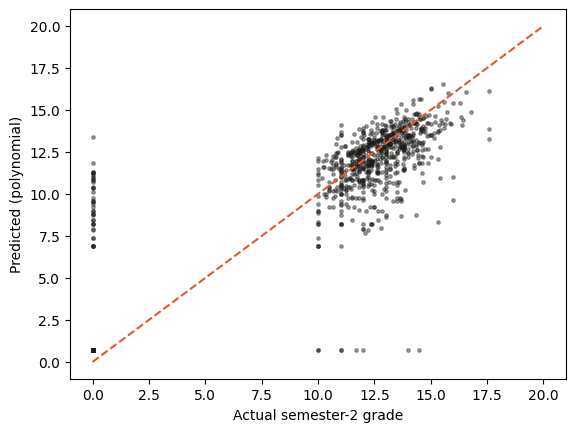

In [13]:
X_r, y_r = df[[S1G, S1A]], df[S2G]
Xtr, Xte, ytr, yte = train_test_split(X_r, y_r, test_size=0.2, random_state=RANDOM_STATE)
for name, model in {"Multiple linear": LinearRegression(),
                    "Polynomial (degree 2)": make_pipeline(PolynomialFeatures(2), LinearRegression())}.items():
    pred = model.fit(Xtr, ytr).predict(Xte)
    print(f"{name}: R2 = {r2_score(yte, pred):.3f}, RMSE = {np.sqrt(mean_squared_error(yte, pred)):.3f}")
plt.scatter(yte, pred, s=6, alpha=.4, color="#1c1b19"); plt.plot([0, 20], [0, 20], "--", color="#e4572e")
plt.xlabel("Actual semester-2 grade"); plt.ylabel("Predicted (polynomial)"); plt.show()

## 6. Clustering (Module 4: K-means and agglomerative clustering)

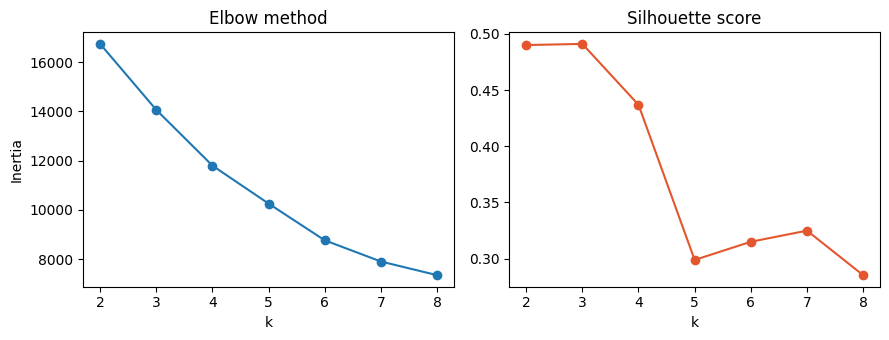

Best k by silhouette: 3


In [14]:
clu_cols = ["Age at enrollment", "Admission grade", S1A, S1G, S2G, "Tuition fees up to date"]
Xs = StandardScaler().fit_transform(df[clu_cols])
ks, inertia, sil = range(2, 9), [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xs)
    inertia.append(km.inertia_); sil.append(silhouette_score(Xs, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
ax[0].plot(ks, inertia, "o-"); ax[0].set(title="Elbow method", xlabel="k", ylabel="Inertia")
ax[1].plot(ks, sil, "o-", color="#e4572e"); ax[1].set(title="Silhouette score", xlabel="k")
plt.tight_layout(); plt.show()
best_k = list(ks)[int(np.argmax(sil))]
print("Best k by silhouette:", best_k)

In [15]:
# Profile of each cluster
labels = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE).fit_predict(Xs)
profile = df[clu_cols + ["Dropout"]].groupby(labels).mean().round(2)
profile["size"] = pd.Series(labels).value_counts().sort_index()
profile.sort_values("Dropout")

,Age at enrollment,Admission grade,Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 2nd sem (grade),Tuition fees up to date,Dropout,size
2,22.41,127.30,5.86,12.79,12.70,1.0,0.15,3283
1,24.64,127.23,0.37,2.07,0.73,1.0,0.75,619
0,26.99,124.64,2.58,7.27,5.94,0.0,0.87,522


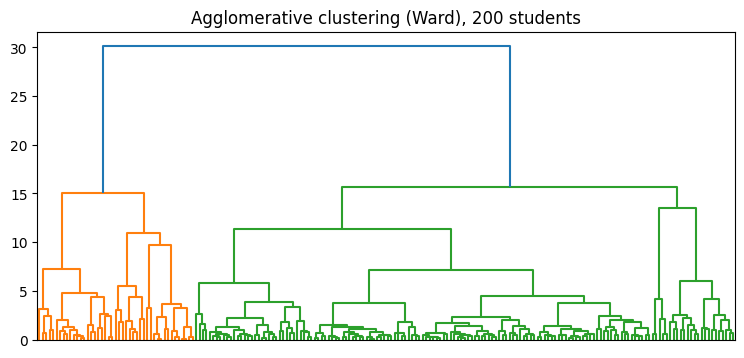

In [16]:
# Agglomerative clustering (Ward) on a 200-student sample
sample = Xs[np.random.RandomState(RANDOM_STATE).choice(len(Xs), 200, False)]
plt.figure(figsize=(9, 4)); dendrogram(linkage(sample, method="ward"), no_labels=True)
plt.title("Agglomerative clustering (Ward), 200 students"); plt.show()

## 7. Classification (Module 4: Logistic Regression, KNN, Decision Tree)
Stratified 80/20 split. Scaling sits inside each pipeline. `class_weight="balanced"` handles the class imbalance.
Each model is tuned with 5-fold cross-validation; the best model is chosen by **cross-validated recall**.

In [17]:
X, y = df.drop(columns=["Target", "Dropout"]), df["Dropout"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
models = {
    "Logistic Regression": (Pipeline([("scaler", StandardScaler()),
                                      ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
                            {"clf__C": [0.1, 1, 10]}),
    "KNN": (Pipeline([("scaler", StandardScaler()), ("clf", KNeighborsClassifier())]),
            {"clf__n_neighbors": [5, 11, 21, 31]}),
    "Decision Tree": (Pipeline([("clf", DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE))]),
                      {"clf__max_depth": [3, 5, 7, 10]}),
}
print(X_train.shape, X_test.shape)

(3539, 36) (885, 36)


In [18]:
fitted, rows = {}, []
for name, (pipe, grid) in models.items():
    best = GridSearchCV(pipe, grid, scoring="f1", cv=cv).fit(X_train, y_train).best_estimator_
    cvs = cross_validate(best, X_train, y_train, cv=cv, scoring=["f1", "recall"])
    pred, prob = best.predict(X_test), best.predict_proba(X_test)[:, 1]
    rows.append({"Model": name, "Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred), "ROC-AUC": roc_auc_score(y_test, prob),
                 "CV F1": cvs["test_f1"].mean(), "CV Recall": cvs["test_recall"].mean()})
    fitted[name] = best
results = pd.DataFrame(rows).set_index("Model")
best_name = results["CV Recall"].idxmax()
print("Selected model (highest CV recall):", best_name)
results.round(3)

Selected model (highest CV recall): Logistic Regression


,Accuracy,Precision,Recall,F1,ROC-AUC,CV F1,CV Recall
Model,,,,,,,
Logistic Regression,0.873,0.787,0.831,0.808,0.927,0.794,0.813
KNN,0.837,0.847,0.602,0.704,0.867,0.702,0.604
Decision Tree,0.847,0.744,0.799,0.771,0.888,0.756,0.768


## 8. Model evaluation (Module 4)

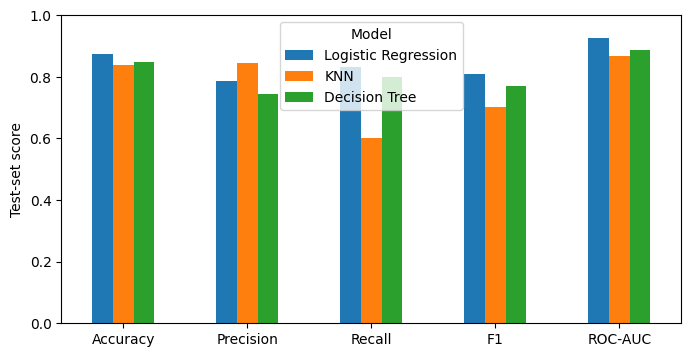

In [19]:
results[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]].T.plot(kind="bar", figsize=(8, 4))
plt.ylim(0, 1); plt.ylabel("Test-set score"); plt.xticks(rotation=0); plt.show()

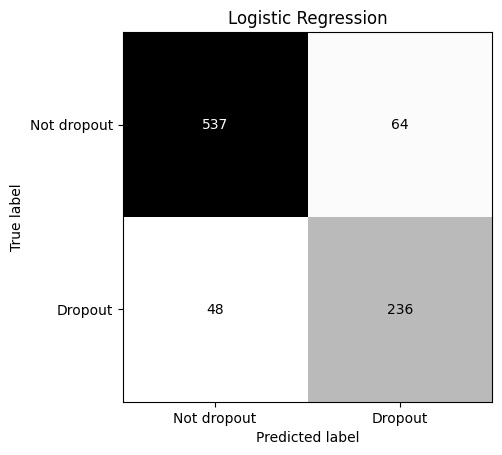

Caught 236 of 284 dropouts; 64 false alarms among 601 students who stayed.


In [20]:
best = fitted[best_name]
cm = confusion_matrix(y_test, best.predict(X_test))
ConfusionMatrixDisplay(cm, display_labels=["Not dropout", "Dropout"]).plot(cmap="Greys", colorbar=False)
plt.title(best_name); plt.show()
tn, fp, fn, tp = cm.ravel()
print(f"Caught {tp} of {tp + fn} dropouts; {fp} false alarms among {tn + fp} students who stayed.")

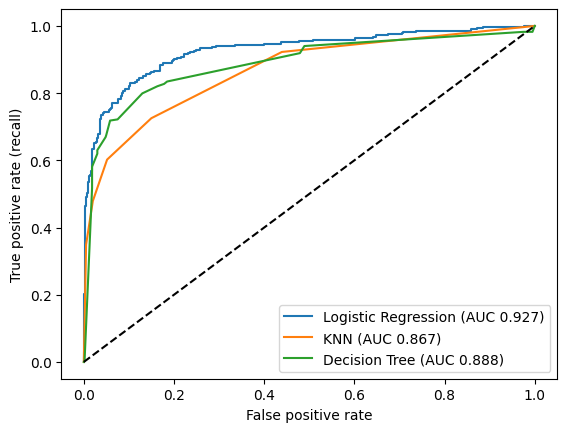

In [21]:
for name, model in fitted.items():
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=f"{name} (AUC {results.loc[name, 'ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("False positive rate"); plt.ylabel("True positive rate (recall)")
plt.legend(); plt.show()

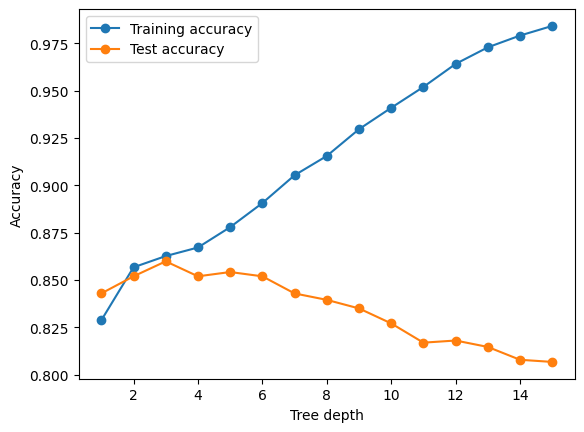

In [22]:
# Overfitting check: decision tree depth vs training and test accuracy
depths, tr_acc, te_acc = range(1, 16), [], []
for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(X_train, y_train)
    tr_acc.append(tree.score(X_train, y_train)); te_acc.append(tree.score(X_test, y_test))
plt.plot(depths, tr_acc, "o-", label="Training accuracy"); plt.plot(depths, te_acc, "o-", label="Test accuracy")
plt.xlabel("Tree depth"); plt.ylabel("Accuracy"); plt.legend(); plt.show()

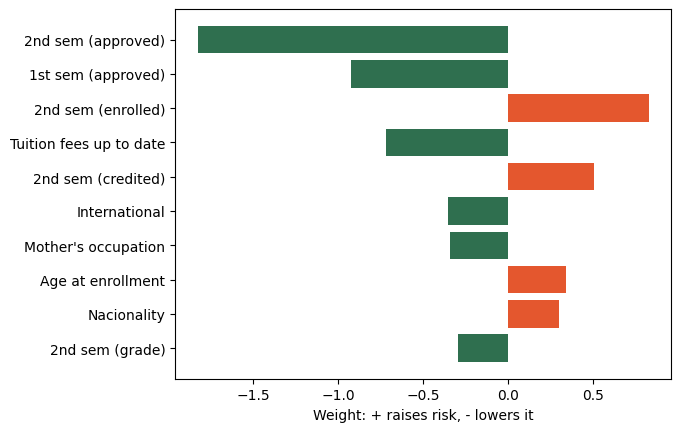

In [23]:
# Explainability: logistic regression weights on standardised inputs
lr = fitted["Logistic Regression"].named_steps["clf"]
weights = pd.Series(lr.coef_[0], X.columns)
top_w = weights.reindex(weights.abs().sort_values(ascending=False).index)[:10][::-1]
plt.barh([n.replace("Curricular units ", "") for n in top_w.index], top_w.values,
         color=["#e4572e" if v > 0 else "#2f6f4f" for v in top_w])
plt.xlabel("Weight: + raises risk, - lowers it"); plt.show()

## 9. Fairness check (Module 6: bias and fairness)

In [24]:
test = X_test.assign(y=y_test.values, pred=best.predict(X_test))
rows = []
for col, names in [("Gender", ["Female", "Male"]), ("Scholarship holder", ["No scholarship", "Scholarship"])]:
    for val, g in test.groupby(col):
        rows.append({"Group": names[val], "Students": len(g), "Actual rate": g["y"].mean(),
                     "Predicted rate": g["pred"].mean(), "Recall": (g["pred"][g["y"] == 1] == 1).mean()})
pd.DataFrame(rows).round(3)

,Group,Students,Actual rate,Predicted rate,Recall
0,Female,564,0.245,0.252,0.812
1,Male,321,0.455,0.492,0.849
2,No scholarship,654,0.390,0.420,0.855
3,Scholarship,231,0.126,0.108,0.621


## 10. Hybrid recommender and its evaluation (Module 5)
**Collaborative part:** find the 5 most similar past students with cosine similarity and see how many dropped out.
**Rule-based part:** simple, documented support rules (assumptions, not learned labels).

In [25]:
scaler = StandardScaler().fit(X_train)
past, past_y = scaler.transform(X_train), y_train.to_numpy()

def rule_suggestions(s):
    tips = []
    if s["Tuition fees up to date"] == 0: tips.append("Fees not up to date: refer to the financial-aid office.")
    if s["Debtor"] == 1: tips.append("Owes money: book a counselling meeting about finances.")
    if s[S1A] / max(s["Curricular units 1st sem (enrolled)"], 1) < 0.5: tips.append("Passed under half of semester-1 subjects: arrange peer tutoring.")
    if s[S2G] < 10: tips.append("Semester-2 average below 10/20: assign an academic mentor.")
    return tips

def recommend(student_row, k=5):
    sims = cosine_similarity(scaler.transform(student_row), past)[0]
    outcomes = past_y[np.argsort(sims)[::-1][:k]]
    tips = rule_suggestions(student_row.iloc[0])
    if outcomes.mean() >= 0.6: tips.insert(0, f"{outcomes.sum()} of {k} similar past students dropped out: schedule a check-in.")
    return tips[:3] or ["No warning signs: continue regular check-ins."]

recommend(X_test.iloc[[0]])

['No warning signs: continue regular check-ins.']

In [26]:
# Evaluate the neighbour signal: flag when 3 or more of the 5 most similar past students dropped out
sims = cosine_similarity(scaler.transform(X_test), past)
share = past_y[np.argsort(-sims, axis=1)[:, :5]].mean(axis=1)
flag = (share >= 0.6).astype(int)
print("Flagged:", flag.sum(), "| accuracy:", round(accuracy_score(y_test, flag), 3),
      "| precision:", round(precision_score(y_test, flag), 3), "| recall:", round(recall_score(y_test, flag), 3))

Flagged: 203 | accuracy: 0.836 | precision: 0.842 | recall: 0.602


## 11. Risk tiers for counsellors
Green < 0.33 ≤ Yellow ≤ 0.66 < Red

In [27]:
prob = best.predict_proba(X_test)[:, 1]
tier = np.where(prob > 0.66, "Red", np.where(prob >= 0.33, "Yellow", "Green"))
pd.Series(tier).value_counts()

Green     512
Red       240
Yellow    133
Name: count, dtype: int64

## 12. Summary
- Early academic progress and unpaid fees are the strongest warning signs of dropout.
- Logistic Regression was selected for its recall and explainability.
- The hybrid recommender turns each prediction into a suggested support action.
- Results are checked for fairness; every flag is reviewed by a counsellor.